# Proyecto 2 — Modelamiento Matemático · Sistema 5
## Tres masas unidas por resortes en triángulo, dentro de una caja con rebotes

**Contenido**

1. Explicación del sistema físico
2. Formulación de las ecuaciones
3. Solución analítica paso a paso (casos donde existe forma cerrada)
4. Explicación del proceso de discretización
5. Discretización e implementación (RK4 propio) con validación contra las soluciones analíticas


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from dataclasses import dataclass

sp.init_printing()

# Colores fijos por masa (m1, m2, m3) en todo el notebook
COLORES = ['#2a78d6', '#eb6834', '#1baf7a']
GRIS = '#555555'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2, 'font.size': 10,
})

---
# 1. El sistema físico

Tres masas $m_1, m_2, m_3$ se mueven en el plano $xy$ dentro de una caja rectangular. Están unidas por tres resortes que forman un triángulo:

| Resorte | Une | Constante | Longitud natural |
|---|---|---|---|
| 1 | $m_1 \leftrightarrow m_2$ | $k_1$ | $L_1$ |
| 2 | $m_2 \leftrightarrow m_3$ | $k_2$ | $L_2$ |
| 3 | $m_1 \leftrightarrow m_3$ | $k_3$ | $L_3$ |

Sobre cada masa actúan:

- **Las fuerzas de los dos resortes que la tocan.** Cada resorte actúa a lo largo de la línea que une sus dos masas. Jala si está estirado y empuja si está comprimido.
- **La gravedad**, $-m_i g$ en la dirección $-y$.
- **La fricción del aire**, que se opone a la velocidad. Usamos el modelo lineal $-b\,\vec v_i$ (ver supuestos).
- **Las paredes de la caja.** No son una fuerza continua: son **eventos de choque** que invierten la componente normal de la velocidad.

### Grados de libertad
Cada masa tiene posición $(x_i, y_i)$ y velocidad $(v_{xi}, v_{yi})$. El estado completo tiene $3 \times 4 = 12$ variables. Por eso el enunciado pide 12 condiciones iniciales.

### Supuestos del modelo (decisiones que el enunciado no fija)

| Decisión | Elección | Justificación |
|---|---|---|
| Forma de las masas | Discos de radio $R$ | Hace falta un tamaño para detectar el choque con la pared |
| Longitud natural $L_s$ | **Distancia inicial** entre cada par | El triángulo arranca relajado; no agrega parámetros a la GUI |
| Fricción | Lineal, $-b\vec v$ (igual $b$ para las tres masas) | Régimen de baja velocidad; mantiene la EDO lineal en $\vec v$ |
| Rebote | Coeficiente de restitución $e$ ($e=1$ elástico) | El enunciado solo dice "rebotar" |
| Choques entre masas | No se modelan | No se piden; los resortes suelen mantenerlas separadas |
| Caja | $[0, W] \times [0, H]$, piso en $y = 0$ | La gravedad apunta hacia el piso |
| Resortes | Sin masa, lineales (ley de Hooke) | Modelo estándar del curso |

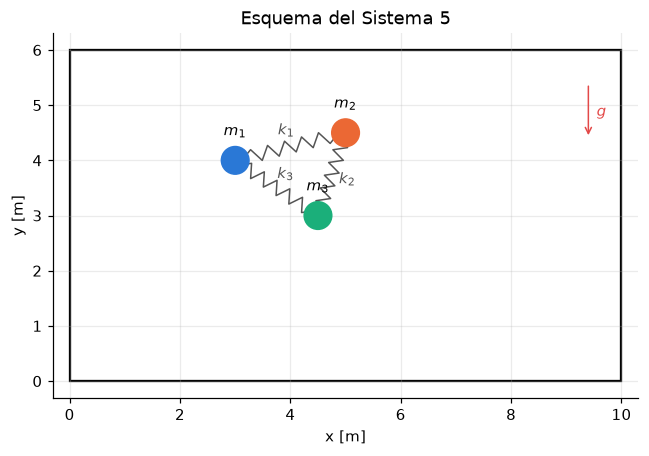

In [3]:
def dibujar_sistema(pos, ancho=10, alto=6, radio=0.25, ax=None, titulo=None):
    '''Dibuja la caja, los tres resortes y las tres masas para una configuración (3x2).'''
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4.3))
    ax.add_patch(plt.Rectangle((0, 0), ancho, alto, fill=False, lw=1.5, color='k'))
    for s, (i, j) in enumerate([(0, 1), (1, 2), (0, 2)]):
        a, b = pos[i], pos[j]
        # resorte como zigzag
        n = 14
        tt = np.linspace(0, 1, n)
        d = b - a; L = np.linalg.norm(d); u = d / L; nrm = np.array([-u[1], u[0]])
        amp = np.zeros(n); amp[2:-2:2] = 0.12; amp[3:-2:2] = -0.12
        pts = a + np.outer(tt, d) + np.outer(amp, nrm)
        ax.plot(pts[:, 0], pts[:, 1], color=GRIS, lw=1)
        mid = a + d / 2 + 0.3 * nrm
        ax.text(*mid, f'$k_{s+1}$', ha='center', va='center', color=GRIS)
    for i in range(3):
        ax.add_patch(plt.Circle(pos[i], radio, color=COLORES[i], zorder=3))
        ax.text(pos[i, 0], pos[i, 1] + radio + 0.2, f'$m_{i+1}$', ha='center')
    ax.annotate('', xy=(ancho - 0.6, alto - 1.6), xytext=(ancho - 0.6, alto - 0.6),
                arrowprops=dict(arrowstyle='->', color='#e34948'))
    ax.text(ancho - 0.45, alto - 1.2, '$g$', color='#e34948')
    ax.set_xlim(-0.3, ancho + 0.3); ax.set_ylim(-0.3, alto + 0.3)
    ax.set_aspect('equal'); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
    ax.set_title(titulo or 'Esquema del Sistema 5')
    return ax

pos_ejemplo = np.array([[3.0, 4.0], [5.0, 4.5], [4.5, 3.0]])
dibujar_sistema(pos_ejemplo); plt.show()

---
# 2. Formulación de las ecuaciones

## 2.1 Fuerza de un resorte en 2D

El resorte $s$ une las masas $i$ y $j$. Lo que lo estira o comprime es la **distancia** entre ellas, no las diferencias en $x$ o en $y$ por separado:

$$
\vec\Delta_{ij} = \vec r_i - \vec r_j, \qquad d_{ij} = \|\vec\Delta_{ij}\| = \sqrt{(x_i-x_j)^2 + (y_i-y_j)^2}, \qquad \hat u_{ij} = \frac{\vec\Delta_{ij}}{d_{ij}}
$$

La ley de Hooke, aplicada a lo largo de la línea que une las masas, da la fuerza **sobre $i$**:

$$
\boxed{\vec F_{ij} = -k_s\,(d_{ij} - L_s)\,\hat u_{ij}}
$$

- $d_{ij} > L_s$ (estirado): la fuerza apunta de $i$ hacia $j$ y **jala**.
- $d_{ij} < L_s$ (comprimido): la fuerza aleja a $i$ de $j$ y **empuja**.
- Tercera ley de Newton: sobre $j$ actúa $\vec F_{ji} = -\vec F_{ij}$.

## 2.2 Segunda ley de Newton para cada masa

$$
m_i\,\ddot{\vec r}_i = \sum_{\text{resortes de } i} \vec F_{ij} \;-\; b\,\dot{\vec r}_i \;-\; m_i g\,\hat y, \qquad i = 1,2,3
$$

Escrita por componentes, con $L_1, L_2, L_3$ las longitudes naturales de los resortes 1, 2 y 3:

$$
\begin{aligned}
m_1\ddot x_1 &= -k_1\,(d_{12}-L_1)\,\frac{x_1-x_2}{d_{12}} \;-\; k_3\,(d_{13}-L_3)\,\frac{x_1-x_3}{d_{13}} \;-\; b\,\dot x_1\\
m_1\ddot y_1 &= -k_1\,(d_{12}-L_1)\,\frac{y_1-y_2}{d_{12}} \;-\; k_3\,(d_{13}-L_3)\,\frac{y_1-y_3}{d_{13}} \;-\; b\,\dot y_1 \;-\; m_1 g\\[4pt]
m_2\ddot x_2 &= -k_1\,(d_{12}-L_1)\,\frac{x_2-x_1}{d_{12}} \;-\; k_2\,(d_{23}-L_2)\,\frac{x_2-x_3}{d_{23}} \;-\; b\,\dot x_2\\
m_2\ddot y_2 &= -k_1\,(d_{12}-L_1)\,\frac{y_2-y_1}{d_{12}} \;-\; k_2\,(d_{23}-L_2)\,\frac{y_2-y_3}{d_{23}} \;-\; b\,\dot y_2 \;-\; m_2 g\\[4pt]
m_3\ddot x_3 &= -k_2\,(d_{23}-L_2)\,\frac{x_3-x_2}{d_{23}} \;-\; k_3\,(d_{13}-L_3)\,\frac{x_3-x_1}{d_{13}} \;-\; b\,\dot x_3\\
m_3\ddot y_3 &= -k_2\,(d_{23}-L_2)\,\frac{y_3-y_2}{d_{23}} \;-\; k_3\,(d_{13}-L_3)\,\frac{y_3-y_1}{d_{13}} \;-\; b\,\dot y_3 \;-\; m_3 g
\end{aligned}
$$

Son **6 EDOs de segundo orden, acopladas y no lineales**:
- **Acopladas**, porque la aceleración de cada masa depende de la posición de las otras.
- **No lineales**, porque $d_{ij}$ contiene una raíz cuadrada y aparece dividiendo. Aunque el resorte sea "lineal" (Hooke), la geometría 2D no lo es.

## 2.3 Reducción a un sistema de primer orden

RK4 integra sistemas de la forma $\dot{\mathbf S} = \mathbf f(t, \mathbf S)$. Para llegar a esa forma, la velocidad pasa a ser una variable propia:

$$
\mathbf S = [\,x_1, y_1, x_2, y_2, x_3, y_3,\; v_{x1}, v_{y1}, v_{x2}, v_{y2}, v_{x3}, v_{y3}\,]^T \in \mathbb R^{12}
$$

$$
\boxed{\;\dot x_i = v_{xi}, \qquad \dot y_i = v_{yi}, \qquad \dot v_{xi} = \frac{F_{xi}}{m_i}, \qquad \dot v_{yi} = \frac{F_{yi}}{m_i}\;}
$$

Quedan **12 EDOs de primer orden**, con condición inicial $\mathbf S(0) = \mathbf S_0$ formada por las 6 posiciones y las 6 velocidades iniciales (12 de los 20 parámetros de la GUI).

## 2.4 Condición de rebote (evento discreto)

Para una caja $[0, W] \times [0, H]$ y masas de radio $R$, una masa toca una pared cuando:

| Pared | Condición | Nueva velocidad |
|---|---|---|
| Izquierda | $x_i < R$ | $v_{xi} \to +e\,\lvert v_{xi}\rvert$ |
| Derecha | $x_i > W - R$ | $v_{xi} \to -e\,\lvert v_{xi}\rvert$ |
| Piso | $y_i < R$ | $v_{yi} \to +e\,\lvert v_{yi}\rvert$ |
| Techo | $y_i > H - R$ | $v_{yi} \to -e\,\lvert v_{yi}\rvert$ |

La componente tangencial no cambia. El rebote **no entra en las EDOs**: se aplica entre pasos de integración (sección 4.5).

**Contacto en reposo.** Con $e < 1$, una masa que rebota en el piso da rebotes cada vez más pequeños y más seguidos: en teoría, infinitos en tiempo finito (paradoja de Zenón). Para evitarlo, si la velocidad normal al tocar la pared es menor que un umbral $v_{\text{reposo}}$ (usamos 0.02 m/s), la masa se deja **apoyada**: se coloca en la pared y su velocidad normal se anula.

## 2.5 Energía mecánica (para validar)

$$
E = \underbrace{\sum_i \tfrac12 m_i \|\vec v_i\|^2}_{\text{cinética}} \;+\; \underbrace{\sum_s \tfrac12 k_s (d_s - L_s)^2}_{\text{elástica}} \;+\; \underbrace{\sum_i m_i g\, y_i}_{\text{gravitatoria}}
$$

Si derivamos $E$ en el tiempo y usamos las EDOs, los términos de resorte y gravedad se cancelan y queda solo la potencia de la fricción:

$$
\frac{dE}{dt} = -\,b\sum_i \|\vec v_i\|^2 \;\le\; 0
$$

**Consecuencia:** con $b = 0$ y $e = 1$ la energía se conserva exactamente. Esta es la primera prueba que debe pasar el código.

In [4]:
# Comprobación simbólica de dE/dt = -b Σ|v|²  (con sympy, para una masa unida a un punto fijo
# es lo mismo; aquí lo hacemos para el sistema completo de 3 masas)
t = sp.symbols('t')
b_, g_ = sp.symbols('b g', positive=True)
ms = sp.symbols('m1:4', positive=True)
ks = sp.symbols('k1:4', positive=True)
Ls = sp.symbols('L1:4', positive=True)
xs = [sp.Function(f'x{i}')(t) for i in range(1, 4)]
ys = [sp.Function(f'y{i}')(t) for i in range(1, 4)]
pares = [(0, 1), (1, 2), (0, 2)]
d = [sp.sqrt((xs[i]-xs[j])**2 + (ys[i]-ys[j])**2) for i, j in pares]

U_el = sum(ks[s]/2*(d[s]-Ls[s])**2 for s in range(3))
U_g = sum(ms[i]*g_*ys[i] for i in range(3))
K = sum(ms[i]/2*(xs[i].diff(t)**2 + ys[i].diff(t)**2) for i in range(3))

# Fuerzas = -grad(U) - b v  →  aceleraciones
acel = {}
for i in range(3):
    acel[xs[i].diff(t, 2)] = (-sp.diff(U_el + U_g, xs[i]) - b_*xs[i].diff(t)) / ms[i]
    acel[ys[i].diff(t, 2)] = (-sp.diff(U_el + U_g, ys[i]) - b_*ys[i].diff(t)) / ms[i]

dEdt = sp.diff(K + U_el + U_g, t).subs(acel)
disipacion = -b_*sum(xs[i].diff(t)**2 + ys[i].diff(t)**2 for i in range(3))
print('dE/dt + bΣ|v|² =', sp.simplify(dEdt - disipacion))

dE/dt + bΣ|v|² = 0


---
# 3. Solución analítica paso a paso

## 3.0 ¿Se puede resolver el sistema completo analíticamente?

**No, en general.** Hay tres razones:

1. **No linealidad geométrica:** $d_{ij} = \sqrt{(x_i-x_j)^2 + (y_i-y_j)^2}$ aparece dividiendo y multiplicando. Las EDOs no son lineales en las posiciones.
2. **Acoplamiento:** 12 ecuaciones de primer orden conectadas entre sí, con masas y constantes arbitrarias.
3. **Rebotes:** cambian la velocidad de forma instantánea en instantes que dependen de la propia solución.

Esto justifica el método numérico. Sin embargo, sí hay **casos exactos** que se resuelven en forma cerrada. Sirven para entender la física y, sobre todo, para **validar el código** en la sección 5:

| Caso | Qué se resuelve | Condición |
|---|---|---|
| 3.1 | Movimiento del **centro de masa** | Masas iguales, entre rebotes |
| 3.2 | **Oscilador amortiguado** genérico, paso a paso | Base para 3.3 y 3.4 |
| 3.3 | **Un resorte** entre dos masas (distancia relativa) | Masas iguales, movimiento sobre la línea que las une |
| 3.4 | **Modo de "respiración"** del triángulo | Masas iguales, $k$ iguales, triángulo equilátero |
| 3.5 | **Frecuencias normales** de pequeñas oscilaciones | Linealización; da el criterio para elegir $h$ |

---
## 3.1 Centro de masa: un proyectil con fricción lineal

**Paso 1: sumar las tres ecuaciones de Newton.** Las fuerzas de los resortes son internas y vienen en pares $\vec F_{ij} = -\vec F_{ji}$, así que se cancelan:

$$
\sum_i m_i \ddot{\vec r}_i = -b\sum_i \dot{\vec r}_i - \Big(\sum_i m_i\Big) g\,\hat y
$$

**Paso 2: escribirlo en términos del centro de masa.** Con $M = m_1+m_2+m_3$ y $\vec R = \frac1M\sum m_i\vec r_i$, el lado izquierdo es $M\ddot{\vec R}$. El término de fricción $\sum_i \dot{\vec r}_i$ es igual a $\frac{M}{m}\dot{\vec R}$ **solo si las masas son iguales** ($m_i = m$). En ese caso, con $\gamma = b/m$:

$$
\ddot{\vec R} = -\gamma\,\dot{\vec R} - g\,\hat y
$$

(Si las masas son distintas, el centro de masa queda acoplado al movimiento interno y no tiene solución cerrada por sí solo.)

**Paso 3: componente $x$.** Con $V_x = \dot X$ la ecuación es de variables separables:

$$
\frac{dV_x}{dt} = -\gamma V_x \;\Rightarrow\; \int_{V_{x0}}^{V_x}\frac{dV}{V} = -\gamma\int_0^t dt' \;\Rightarrow\; \boxed{V_x(t) = V_{x0}\,e^{-\gamma t}}
$$

Integrando otra vez:

$$
\boxed{X(t) = X_0 + \frac{V_{x0}}{\gamma}\big(1 - e^{-\gamma t}\big)}
$$

La masa avanza como máximo $V_{x0}/\gamma$ en horizontal.

**Paso 4: componente $y$, por factor integrante.** Partimos de $\dot V_y + \gamma V_y = -g$ y multiplicamos por $e^{\gamma t}$:

$$
\frac{d}{dt}\big(V_y e^{\gamma t}\big) = -g\,e^{\gamma t} \;\Rightarrow\; V_y e^{\gamma t} - V_{y0} = -\frac{g}{\gamma}\big(e^{\gamma t} - 1\big)
$$

$$
\boxed{V_y(t) = -\frac{g}{\gamma} + \Big(V_{y0} + \frac{g}{\gamma}\Big)e^{-\gamma t}}
$$

$-g/\gamma$ es la **velocidad terminal**. Integrando:

$$
\boxed{Y(t) = Y_0 - \frac{g}{\gamma}\,t + \frac{1}{\gamma}\Big(V_{y0} + \frac{g}{\gamma}\Big)\big(1 - e^{-\gamma t}\big)}
$$

**Paso 5: comprobación del límite sin fricción.** Si $\gamma \to 0$, $Y(t) \to Y_0 + V_{y0}t - \tfrac12 g t^2$: la parábola del tiro sin fricción. Lo verificamos con sympy:

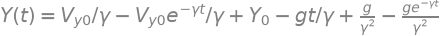

Límite γ→0 de Y(t):


In [5]:
t = sp.symbols('t', nonnegative=True)
gam, g, X0, Y0, Vx0, Vy0 = sp.symbols('gamma g X0 Y0 V_x0 V_y0', positive=True)
Vx = sp.Function('V_x'); Vy = sp.Function('V_y')

# Resolver con dsolve las dos EDOs de velocidad
sol_vx = sp.dsolve(sp.Eq(Vx(t).diff(t), -gam*Vx(t)), Vx(t), ics={Vx(0): Vx0})
sol_vy = sp.dsolve(sp.Eq(Vy(t).diff(t), -gam*Vy(t) - g), Vy(t), ics={Vy(0): Vy0})
display(sol_vx, sol_vy)

# Integrar para obtener posiciones
X_t = X0 + sp.integrate(sol_vx.rhs.subs(t, sp.Symbol('s')), (sp.Symbol('s'), 0, t))
Y_t = Y0 + sp.integrate(sol_vy.rhs.subs(t, sp.Symbol('s')), (sp.Symbol('s'), 0, t))
display(sp.Eq(sp.Symbol('X(t)'), sp.simplify(X_t)), sp.Eq(sp.Symbol('Y(t)'), sp.simplify(Y_t)))

# Límite sin fricción
print('Límite γ→0 de Y(t):')
display(sp.limit(Y_t, gam, 0))

---
## 3.2 El oscilador armónico amortiguado, paso a paso

Los casos 3.3 y 3.4 llevan a la misma ecuación, para una variable $u(t)$ que mide la deformación del resorte:

$$
\ddot u + \gamma\,\dot u + \omega_0^2\,u = 0, \qquad u(0) = u_0,\quad \dot u(0) = v_0
$$

**Paso 1: ansatz exponencial.** Probamos $u = e^{\lambda t}$ y sustituimos:

$$
(\lambda^2 + \gamma\lambda + \omega_0^2)\,e^{\lambda t} = 0 \;\Rightarrow\; \lambda^2 + \gamma\lambda + \omega_0^2 = 0
$$

**Paso 2: raíces de la ecuación característica.**

$$
\lambda_{1,2} = -\frac{\gamma}{2} \pm \sqrt{\frac{\gamma^2}{4} - \omega_0^2}
$$

**Paso 3: tres regímenes según el discriminante.**

| Régimen | Condición | Solución general |
|---|---|---|
| Subamortiguado | $\gamma < 2\omega_0$ | $u = e^{-\gamma t/2}\big(A\cos\omega_d t + B\sin\omega_d t\big)$, con $\omega_d = \sqrt{\omega_0^2 - \gamma^2/4}$ |
| Crítico | $\gamma = 2\omega_0$ | $u = (A + Bt)\,e^{-\gamma t/2}$ |
| Sobreamortiguado | $\gamma > 2\omega_0$ | $u = A e^{\lambda_1 t} + B e^{\lambda_2 t}$ |

**Paso 4: constantes con las condiciones iniciales (caso subamortiguado, el de nuestro sistema).**

- $u(0) = A = u_0$
- $\dot u(0) = -\frac{\gamma}{2}A + \omega_d B = v_0 \;\Rightarrow\; B = \dfrac{v_0 + \gamma u_0/2}{\omega_d}$

$$
\boxed{u(t) = e^{-\gamma t/2}\left[u_0\cos\omega_d t + \frac{v_0 + \gamma u_0/2}{\omega_d}\sin\omega_d t\right]}
$$

Interpretación: la amplitud decae como $e^{-\gamma t/2}$ y el sistema oscila con frecuencia $\omega_d$, un poco menor que $\omega_0$.

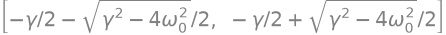

Residuo de la EDO : 0
u(0)  = u_0
u'(0) = v_0


In [6]:
w0, gam = sp.symbols('omega_0 gamma', positive=True)
u0, v0 = sp.symbols('u_0 v_0', real=True)
u = sp.Function('u')
ode = sp.Eq(u(t).diff(t, 2) + gam*u(t).diff(t) + w0**2*u(t), 0)

# Ecuación característica y sus raíces
lam = sp.symbols('lambda')
display(sp.Eq(lam**2 + gam*lam + w0**2, 0), sp.solve(lam**2 + gam*lam + w0**2, lam))

# Nuestra solución subamortiguada: verificar que cumple la EDO y las condiciones iniciales
wd = sp.sqrt(w0**2 - gam**2/4)
u_sol = sp.exp(-gam*t/2)*(u0*sp.cos(wd*t) + (v0 + gam*u0/2)/wd*sp.sin(wd*t))
print('Residuo de la EDO :', sp.simplify(u_sol.diff(t, 2) + gam*u_sol.diff(t) + w0**2*u_sol))
print('u(0)  =', sp.simplify(u_sol.subs(t, 0)))
print("u'(0) =", sp.simplify(u_sol.diff(t).subs(t, 0)))

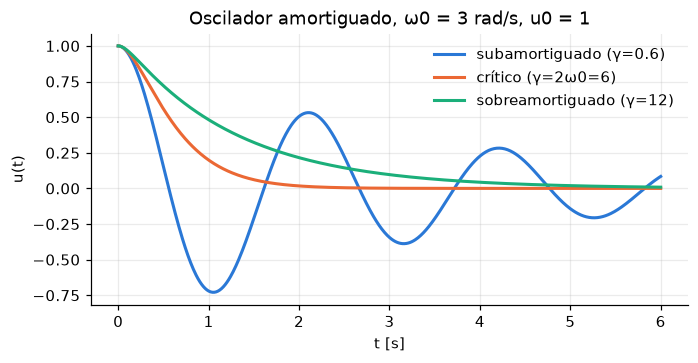

In [7]:
def oscilador_amortiguado(t, u0, v0, w0, gamma):
    '''Solución exacta de u'' + γu' + ω0²u = 0 en los tres regímenes (vectorizada en t).'''
    t = np.asarray(t, float)
    disc = gamma**2 / 4 - w0**2
    if np.isclose(disc, 0.0):                       # crítico
        lam = -gamma / 2
        return (u0 + (v0 - lam*u0)*t) * np.exp(lam*t)
    raiz = np.sqrt(complex(disc))
    l1, l2 = -gamma/2 + raiz, -gamma/2 - raiz        # sub- o sobreamortiguado
    C1 = (v0 - l2*u0) / (l1 - l2)
    C2 = (l1*u0 - v0) / (l1 - l2)
    return np.real(C1*np.exp(l1*t) + C2*np.exp(l2*t))

tt = np.linspace(0, 6, 600)
fig, ax = plt.subplots(figsize=(7, 3.2))
for gm, nombre, c in [(0.6, 'subamortiguado (γ=0.6)', COLORES[0]),
                      (6.0, 'crítico (γ=2ω0=6)', COLORES[1]),
                      (12.0, 'sobreamortiguado (γ=12)', COLORES[2])]:
    ax.plot(tt, oscilador_amortiguado(tt, 1.0, 0.0, 3.0, gm), color=c, label=nombre)
ax.set_xlabel('t [s]'); ax.set_ylabel('u(t)'); ax.set_title('Oscilador amortiguado, ω0 = 3 rad/s, u0 = 1')
ax.legend(frameon=False); plt.show()

---
## 3.3 Un resorte entre dos masas iguales: la distancia relativa

Apagamos los resortes 2 y 3 ($k_2 = k_3 = 0$). Las masas $m_1 = m_2 = m$ están sobre una recta horizontal y se mueven a lo largo de ella, con la misma $v_y$ inicial.

**Paso 1: ecuaciones de cada masa en $x$.** Con $m_1$ a la izquierda, $d = x_2 - x_1$:

$$
m\ddot x_1 = +k(d - L) - b\dot x_1, \qquad m\ddot x_2 = -k(d - L) - b\dot x_2
$$

**Paso 2: restar** (ecuación 2 menos ecuación 1) y definir la deformación $u = d - L$:

$$
m\ddot u = -2k\,u - b\,\dot u \;\Rightarrow\; \boxed{\ddot u + \gamma\dot u + \omega_0^2 u = 0,\qquad \omega_0^2 = \frac{2k}{m},\;\; \gamma = \frac{b}{m}}
$$

**Paso 3: ¿qué pasa con la gravedad?** Afecta a las dos masas por igual, así que desaparece al restar. Las dos caen juntas (centro de masa, sección 3.1) mientras $u$ oscila según la sección 3.2.

> En general, con masas distintas, $\omega_0^2 = k/\mu$ con $\mu = \frac{m_1 m_2}{m_1+m_2}$ (masa reducida). Para $m_1 = m_2 = m$, $\mu = m/2$ y se recupera $2k/m$.

---
## 3.4 Modo de "respiración" del triángulo equilátero (caso exacto con los 3 resortes)

Supuestos: $m_1=m_2=m_3=m$, $k_1=k_2=k_3=k$, y las masas en los vértices de un triángulo equilátero de lado $L$ (la longitud natural). Cada masa está a distancia $\rho_0 = L/\sqrt3$ del centroide. Si cada masa recibe una velocidad **radial** (hacia afuera o hacia adentro, de igual magnitud), por simetría el triángulo **sigue siendo equilátero** todo el tiempo: solo cambia de tamaño.

**Paso 1: geometría.** Si la distancia al centroide es $\rho$, el lado es $d = \sqrt3\,\rho$.

**Paso 2: fuerza radial sobre una masa.** Los dos resortes que la tocan tienen tensión $T = k(d - L) = k\sqrt3(\rho - \rho_0)$. Cada uno forma $30^\circ$ con la dirección radial, así que la componente radial total es:

$$
F_\rho = -2T\cos 30^\circ = -2\,k\sqrt3(\rho-\rho_0)\,\frac{\sqrt3}{2} = -3k\,(\rho - \rho_0)
$$

**Paso 3: ecuación radial.** Con $u = \rho - \rho_0$ y la fricción lineal:

$$
\boxed{\ddot u + \gamma\dot u + \omega_0^2 u = 0,\qquad \omega_0^2 = \frac{3k}{m}}
$$

El resultado es **exacto, no una aproximación de amplitud pequeña**: la simetría elimina la no linealidad. La gravedad solo mueve el centro de masa (sección 3.1). La solución completa es

$$
\vec r_i(t) = \vec R(t) + \big(\rho_0 + u(t)\big)\,\hat e_i,
$$

donde $\hat e_i$ es la dirección fija del centroide al vértice $i$, $\vec R(t)$ viene de 3.1 y $u(t)$ de 3.2. Es una **solución analítica exacta del sistema completo de 12 EDOs**, ideal para medir el error de RK4.

---
## 3.5 Frecuencias normales (linealización): ¿qué tan rápido puede oscilar el sistema?

Cerca del equilibrio ($b = 0$, $g = 0$), las ecuaciones se linealizan como $M\ddot{\vec q} = -K\vec q$, donde $K$ es el **hessiano** de la energía elástica evaluado en el equilibrio. Las frecuencias normales son $\omega^2 = $ autovalores de $M^{-1}K$. Las calculamos simbólicamente para el triángulo equilátero:

In [8]:
k, m, L = sp.symbols('k m L', positive=True)
q = sp.symbols('x1 y1 x2 y2 x3 y3', real=True)
r = [sp.Matrix(q[0:2]), sp.Matrix(q[2:4]), sp.Matrix(q[4:6])]
U = sum(k/2*(sp.sqrt(((r[i]-r[j]).T*(r[i]-r[j]))[0]) - L)**2 for i, j in [(0, 1), (1, 2), (0, 2)])

equilibrio = {q[0]: 0, q[1]: 0, q[2]: L, q[3]: 0, q[4]: L/2, q[5]: sp.sqrt(3)*L/2}
Kmat = sp.simplify(sp.hessian(U, q).subs(equilibrio))
print('Matriz de rigidez K (hessiano en el equilibrio):'); display(Kmat)
print('Autovalores ω² de M⁻¹K  {valor: multiplicidad}:'); display((Kmat/m).eigenvals())

Matriz de rigidez K (hessiano en el equilibrio):


⎡ 5⋅k     √3⋅k                    -k     -√3⋅k ⎤
⎢ ───     ────     -k      0      ───    ──────⎥
⎢  4       4                       4       4   ⎥
⎢                                              ⎥
⎢ √3⋅k    3⋅k                    -√3⋅k   -3⋅k  ⎥
⎢ ────    ───      0       0     ──────  ───── ⎥
⎢  4       4                       4       4   ⎥
⎢                                              ⎥
⎢                 5⋅k    -√3⋅k    -k      √3⋅k ⎥
⎢  -k      0      ───    ──────   ───     ──── ⎥
⎢                  4       4       4       4   ⎥
⎢                                              ⎥
⎢                -√3⋅k    3⋅k     √3⋅k   -3⋅k  ⎥
⎢  0       0     ──────   ───     ────   ───── ⎥
⎢                  4       4       4       4   ⎥
⎢                                              ⎥
⎢ -k     -√3⋅k    -k      √3⋅k     k           ⎥
⎢ ───    ──────   ───     ────     ─       0   ⎥
⎢  4       4       4       4       2           ⎥
⎢                                              ⎥
⎢-√3⋅k   -3⋅k     √3

Autovalores ω² de M⁻¹K  {valor: multiplicidad}:


**Interpretación de los 6 modos:**

- $\omega^2 = 0$ (×3): **traslación en $x$, traslación en $y$ y rotación rígida**. Mover o girar el triángulo entero no deforma ningún resorte.
- $\omega^2 = \tfrac{3k}{2m}$ (×2): dos modos de **deformación** (cizalla) degenerados.
- $\omega^2 = \tfrac{3k}{m}$ (×1): el **modo de respiración** de la sección 3.4, que confirma ese resultado.

**Consecuencia numérica:** la oscilación más rápida tiene $\omega_{\max} = \sqrt{3k/m}$, con período $T_{\min} = 2\pi/\omega_{\max}$. El paso $h$ de RK4 debe ser mucho menor que $T_{\min}$ (sección 4.4).

Para masas y constantes **distintas**, una estimación conservadora (cota tipo Gershgorin sobre $M^{-1}K$) es

$$
\omega_{\max}^2 \lesssim 2.5\,\max_i \frac{\sum_{s \ni i} k_s}{m_i},
$$

donde la suma recorre los resortes $s$ que tocan la masa $i$. Para el equilátero da $2.5\cdot 2k/m = 5k/m \ge 3k/m$ ✓.

---
# 4. El proceso de discretización

## 4.1 Idea central: del tiempo continuo a una malla de tiempos

La EDO $\dot{\mathbf S} = \mathbf f(t, \mathbf S)$ define $\mathbf S(t)$ para **todo** $t$. Un computador solo puede guardar valores en **instantes discretos**:

$$
t_n = t_0 + n\,h, \qquad n = 0, 1, 2, \dots, N, \qquad \mathbf S_n \approx \mathbf S(t_n)
$$

Discretizar es reemplazar la EDO por una **regla de actualización** $\mathbf S_{n+1} = \Phi(t_n, \mathbf S_n, h)$ que avanza de un instante al siguiente. El punto de partida es la forma integral exacta:

$$
\mathbf S(t_{n+1}) = \mathbf S(t_n) + \int_{t_n}^{t_{n+1}} \mathbf f\big(t, \mathbf S(t)\big)\,dt
$$

Cada método numérico es una forma distinta de **aproximar esa integral**.

## 4.2 Primer intento: Euler explícito (y por qué no basta)

Aproximar la integral con un rectángulo (la pendiente al inicio del intervalo) da:

$$
\mathbf S_{n+1} = \mathbf S_n + h\,\mathbf f(t_n, \mathbf S_n)
$$

Es equivalente a la derivada por diferencia hacia adelante, $\dot{\mathbf S} \approx (\mathbf S_{n+1} - \mathbf S_n)/h$. Su error local es $O(h^2)$ y su error global es $O(h)$.

**Problema para resortes:** en un oscilador sin fricción $\ddot u = -\omega^2 u$, un paso de Euler multiplica la amplitud por $|1 + i\omega h| = \sqrt{1 + \omega^2h^2} > 1$. La energía **crece en cada paso**, sin importar cuán pequeño sea $h$. Para un sistema de resortes que debe conservar energía, Euler es cualitativamente incorrecto.

## 4.3 Runge–Kutta de orden 4 (RK4)

RK4 evalúa la pendiente **cuatro veces** dentro del intervalo y las combina con los pesos de la regla de Simpson:

$$
\begin{aligned}
\mathbf k_1 &= \mathbf f\big(t_n,\; \mathbf S_n\big) && \text{pendiente al inicio}\\
\mathbf k_2 &= \mathbf f\big(t_n + \tfrac h2,\; \mathbf S_n + \tfrac h2\mathbf k_1\big) && \text{en el punto medio, usando } \mathbf k_1\\
\mathbf k_3 &= \mathbf f\big(t_n + \tfrac h2,\; \mathbf S_n + \tfrac h2\mathbf k_2\big) && \text{en el punto medio, usando } \mathbf k_2\\
\mathbf k_4 &= \mathbf f\big(t_n + h,\; \mathbf S_n + h\,\mathbf k_3\big) && \text{al final}\\[4pt]
\mathbf S_{n+1} &= \mathbf S_n + \frac h6\big(\mathbf k_1 + 2\mathbf k_2 + 2\mathbf k_3 + \mathbf k_4\big)
\end{aligned}
$$

- Los pesos $\tfrac16, \tfrac26, \tfrac26, \tfrac16$ son los de Simpson ($\tfrac16, \tfrac46, \tfrac16$), con el punto medio repartido entre $\mathbf k_2$ y $\mathbf k_3$.
- **Error local** $O(h^5)$ y **error global** $O(h^4)$: si $h$ se divide por 2, el error se divide por $\approx 16$. Lo comprobamos en la sección 5.6.
- **Costo:** 4 evaluaciones de $\mathbf f$ por paso.
- **Importante:** cada $\mathbf k$ es un **vector de 12 componentes**. El método se aplica al estado completo a la vez, nunca componente por componente. Así se respeta el acoplamiento entre masas.

## 4.4 Elección del paso $h$: estabilidad y precisión

- **Estabilidad:** para un oscilador sin fricción, RK4 es estable si $\omega h \lesssim 2.83$. Por encima, la solución numérica explota.
- **Precisión:** para que el error sea pequeño se necesita $\omega_{\max} h \ll 1$. Una regla práctica es $h \le T_{\min}/100$, con $T_{\min} = 2\pi/\omega_{\max}$ de la sección 3.5.
- **Rebotes:** si el choque se aplica solo al final del paso, se detecta con un retraso de hasta un paso y el error es $O(h)$ por rebote. Por eso localizamos el instante del choque dentro del paso (sección 4.5).
- Con $k \sim 10^1$–$10^2$ N/m y $m \sim 1$ kg, $h = 10^{-3}$ s es un buen valor por defecto.

## 4.5 Discretización de los rebotes: localización del evento

Los rebotes son discontinuidades en la velocidad, así que **no se integran**: se tratan como **eventos** entre pasos de RK4.

**Versión simple (primer orden).** Se da el paso completo y, si una masa quedó fuera, se refleja su posición en el borde ($x \to 2(W-R) - x$) y se invierte la velocidad normal. Es fácil, pero el choque ocurre "tarde": dentro del paso la masa sigue sintiendo los resortes y la gravedad como si la pared no existiera. Eso deja un error de energía $O(h)$ en **cada** rebote. Lo medimos en la prueba E.

**Versión con localización del evento (la que usamos).** Se busca el instante del choque dentro del paso:

1. Se intenta el paso completo: $\mathbf S^* = \text{RK4}(\mathbf S_n, h)$. Si ninguna masa salió de la caja, se acepta.
2. Si alguna salió, se busca por **bisección** la fracción de paso $\tau \in (0, h]$ en la que una masa toca la pared. La función evento es $g(\tau) = $ máxima penetración de $\text{RK4}(\mathbf S_n, \tau)$, y se reduce el intervalo hasta un ancho de $10^{-9}$ s.
3. Se avanza exactamente hasta $\tau$ y se aplica la ley de choque:
   - $v_n \to -e\,v_n$, con el signo que apunta hacia adentro (el valor absoluto evita un doble rebote);
   - **contacto en reposo** si $|v_n| < v_{\text{reposo}}$.
4. Se integra el resto del paso, $h - \tau$, repitiendo desde 1 por si hay otro choque.

Este es el mismo principio que usan los integradores profesionales con detección de eventos (por ejemplo, `events` en `solve_ivp`), pero programado por nosotros. El error del rebote baja de $O(h)$ a prácticamente la tolerancia de la bisección.

## 4.6 Algoritmo completo

```
entrada: 20 parámetros, caja (W, H, R), e, h, T
L_s ← distancias iniciales entre cada par
S_0 ← [posiciones iniciales, velocidades iniciales]
para n = 0 … N−1:
    k1 ← f(t_n,       S_n)
    k2 ← f(t_n + h/2, S_n + h/2·k1)
    k3 ← f(t_n + h/2, S_n + h/2·k2)
    k4 ← f(t_n + h,   S_n + h·k3)
    S* ← S_n + h/6·(k1 + 2k2 + 2k3 + k4)
    si ninguna masa salió de la caja:  S_{n+1} ← S*
    si no:  τ ← bisección del instante de choque en (0, h]
            S ← RK4(S_n, τ);  invertir v_n (×e) o dejar en reposo
            integrar el resto h − τ (repetir si hay otro choque)
    t_{n+1} ← t_n + h
```

donde $\mathbf f$ evalúa las fuerzas de la sección 2 en el estado que recibe.

---
# 5. Discretización e implementación

## 5.1 Parámetros del sistema

Los 20 parámetros del enunciado, más las constantes de diseño (caja, radio, $e$, $L_s$). Esta misma estructura la puede llenar la GUI.

In [9]:
RESORTES = [(0, 1), (1, 2), (0, 2)]   # resorte 1: m1-m2, resorte 2: m2-m3, resorte 3: m1-m3

@dataclass
class Parametros:
    pos0: np.ndarray          # (3,2) posiciones iniciales  [m]     -> 6 parámetros
    vel0: np.ndarray          # (3,2) velocidades iniciales [m/s]   -> 6 parámetros
    k: np.ndarray             # (3,)  k1, k2, k3            [N/m]   -> 3 parámetros
    b: float                  # fricción del aire           [kg/s]  -> 1 parámetro
    m: np.ndarray             # (3,)  m1, m2, m3            [kg]    -> 3 parámetros
    g: float                  # gravedad                    [m/s²]  -> 1 parámetro
    # --- decisiones de diseño (no están en el enunciado) ---
    ancho: float = 10.0       # W [m]
    alto: float = 6.0         # H [m]
    radio: float = 0.25       # R [m]
    e: float = 1.0            # coeficiente de restitución
    L0: np.ndarray = None     # longitudes naturales; None -> distancias iniciales
    rebotes: bool = True      # False = espacio libre (para las pruebas analíticas)

    def __post_init__(self):
        self.pos0 = np.asarray(self.pos0, float).reshape(3, 2)
        self.vel0 = np.asarray(self.vel0, float).reshape(3, 2)
        self.k = np.asarray(self.k, float)
        self.m = np.asarray(self.m, float)
        if self.L0 is None:
            self.L0 = np.array([np.linalg.norm(self.pos0[i] - self.pos0[j]) for i, j in RESORTES])
        if self.rebotes:
            R = self.radio
            assert np.all((self.pos0[:, 0] >= R) & (self.pos0[:, 0] <= self.ancho - R) &
                          (self.pos0[:, 1] >= R) & (self.pos0[:, 1] <= self.alto - R)), \
                'Las posiciones iniciales deben estar dentro de la caja'

    def estado_inicial(self):
        return np.concatenate([self.pos0.ravel(), self.vel0.ravel()])

    def h_sugerido(self, puntos_por_periodo=100):
        '''h ≤ T_min / 100 con la estimación conservadora de ω_max (sección 3.5).'''
        suma_k = np.zeros(3)
        for s, (i, j) in enumerate(RESORTES):
            suma_k[i] += self.k[s]; suma_k[j] += self.k[s]
        w_max = np.sqrt(2.5 * np.max(suma_k / self.m))
        return 2*np.pi / w_max / puntos_por_periodo if w_max > 0 else 1e-2

## 5.2 Lado derecho de las EDOs: $\mathbf f(t, \mathbf S)$

Es la traducción directa de la sección 2.3. Cada resorte se calcula **una sola vez** y se suma con signos opuestos a sus dos masas (tercera ley de Newton).

In [10]:
def derivadas(t, S, p):
    '''f(t,S): devuelve dS/dt (12 componentes) para el estado S.'''
    r = S[:6].reshape(3, 2)          # posiciones
    v = S[6:].reshape(3, 2)          # velocidades
    F = np.zeros((3, 2))

    # Resortes: F_ij = -k (d - L) û_ij sobre i, y -F_ij sobre j
    for s, (i, j) in enumerate(RESORTES):
        delta = r[i] - r[j]
        dist = np.hypot(*delta)
        if dist > 1e-12:                         # evita dividir por 0 si coinciden
            f = -p.k[s] * (dist - p.L0[s]) * delta / dist
            F[i] += f
            F[j] -= f

    F -= p.b * v                     # fricción lineal
    F[:, 1] -= p.m * p.g             # gravedad en -y

    a = F / p.m[:, None]
    return np.concatenate([v.ravel(), a.ravel()])

## 5.3 Un paso de RK4 y un paso de Euler (para comparar)

Las fórmulas de la sección 4.3, aplicadas al vector de estado completo.

In [11]:
def paso_rk4(f, t, S, h, p):
    k1 = f(t,         S,             p)
    k2 = f(t + h/2,   S + h/2 * k1,  p)
    k3 = f(t + h/2,   S + h/2 * k2,  p)
    k4 = f(t + h,     S + h * k3,    p)
    return S + h/6 * (k1 + 2*k2 + 2*k3 + k4)

def paso_euler(f, t, S, h, p):
    return S + h * f(t, S, p)

## 5.4 Rebotes con localización del evento (sección 4.5)

In [12]:
V_REPOSO = 0.02   # [m/s] por debajo de esta velocidad normal la masa queda apoyada en la pared

def aplicar_rebotes(S, p):
    '''Ley de choque para cada masa fuera de la caja: invierte v_n (×e) o la deja en reposo.
    Si la masa está fuera, también refleja la posición (en la versión con eventos la
    penetración es ~1e-9 m, así que esta reflexión es despreciable).'''
    r = S[:6].reshape(3, 2)          # vistas: modificar r y v modifica S
    v = S[6:].reshape(3, 2)
    R, e = p.radio, p.e
    limites = [(R, p.ancho - R), (R, p.alto - R)]     # eje 0 = x, eje 1 = y
    for i in range(3):
        for eje, (lo, hi) in enumerate(limites):
            for borde, adentro in [(lo, +1), (hi, -1)]:   # adentro = signo de la dirección hacia la caja
                if adentro * (borde - r[i, eje]) > 0:     # la masa está fuera de esta pared
                    if abs(v[i, eje]) < V_REPOSO:         # contacto en reposo
                        r[i, eje] = borde
                        v[i, eje] = 0.0
                    else:                                 # rebote
                        r[i, eje] = 2*borde - r[i, eje]
                        v[i, eje] = adentro * e * abs(v[i, eje])
    return S

def penetracion(S, p):
    '''Función evento: máxima distancia que una masa ha cruzado una pared moviéndose hacia afuera.'''
    r = S[:6].reshape(3, 2); v = S[6:].reshape(3, 2); R = p.radio
    peor = 0.0
    for eje, (lo, hi) in enumerate([(R, p.ancho - R), (R, p.alto - R)]):
        for i in range(3):
            if r[i, eje] < lo and -v[i, eje] > V_REPOSO: peor = max(peor, lo - r[i, eje])
            if r[i, eje] > hi and  v[i, eje] > V_REPOSO: peor = max(peor, r[i, eje] - hi)
    return peor

def paso_con_eventos(t, S, h, p, tol=1e-9, max_eventos=8):
    '''Un paso de tamaño h que localiza por bisección cada choque con las paredes.'''
    restante = h
    for _ in range(max_eventos):
        S_try = paso_rk4(derivadas, t, S, restante, p)
        if penetracion(S_try, p) == 0:                 # sin choques: aceptar
            return aplicar_rebotes(S_try, p)           # (solo actúa si hay contacto en reposo)
        a, b = 0.0, restante                           # bisección del instante de choque
        while b - a > tol:
            mid = 0.5 * (a + b)
            if penetracion(paso_rk4(derivadas, t, S, mid, p), p) > 0:
                b = mid
            else:
                a = mid
        S = aplicar_rebotes(paso_rk4(derivadas, t, S, b, p), p)   # avanzar hasta el choque y rebotar
        t, restante = t + b, restante - b
        if restante <= tol:
            return S
    return aplicar_rebotes(paso_rk4(derivadas, t, S, restante, p), p)   # salvaguarda

## 5.5 Bucle de simulación y energía

In [13]:
def simular(p, T, h=None, metodo='rk4', eventos=True):
    '''Integra de t=0 a t=T. Devuelve t (N+1,) y S (N+1, 12).
    metodo : 'rk4' o 'euler' (solo para comparar).
    eventos: True  -> rebotes con localización del instante de choque (recomendado)
             False -> rebote simple al final del paso (primer orden, para comparar)'''
    h = h or p.h_sugerido()
    paso = paso_rk4 if metodo == 'rk4' else paso_euler
    N = int(round(T / h))
    t = np.linspace(0, N*h, N + 1)
    S = np.empty((N + 1, 12))
    S[0] = p.estado_inicial()
    for n in range(N):
        if p.rebotes and eventos and metodo == 'rk4':
            S[n+1] = paso_con_eventos(t[n], S[n], h, p)
        else:
            S[n+1] = paso(derivadas, t[n], S[n], h, p)
            if p.rebotes:
                S[n+1] = aplicar_rebotes(S[n+1], p)
    return t, S

def energia(S, p):
    '''Energías cinética, elástica y gravitatoria para cada fila de S.'''
    r = S[:, :6].reshape(-1, 3, 2)
    v = S[:, 6:].reshape(-1, 3, 2)
    Ek = 0.5 * np.sum(p.m * np.sum(v**2, axis=2), axis=1)
    Ee = sum(0.5 * p.k[s] * (np.linalg.norm(r[:, i] - r[:, j], axis=1) - p.L0[s])**2
             for s, (i, j) in enumerate(RESORTES))
    Eg = np.sum(p.m * p.g * r[:, :, 1], axis=1)
    return Ek, Ee, Eg

### Simulación de ejemplo

Valores de ejemplo para los 20 parámetros (los que tendría la GUI por defecto). Las velocidades iniciales son lo bastante grandes para que las masas choquen con las **cuatro** paredes.

h sugerido = 3.97e-03 s   ·   h usado = 1e-03 s
Longitudes naturales L1, L2, L3 = [2.062 1.581 1.803] m


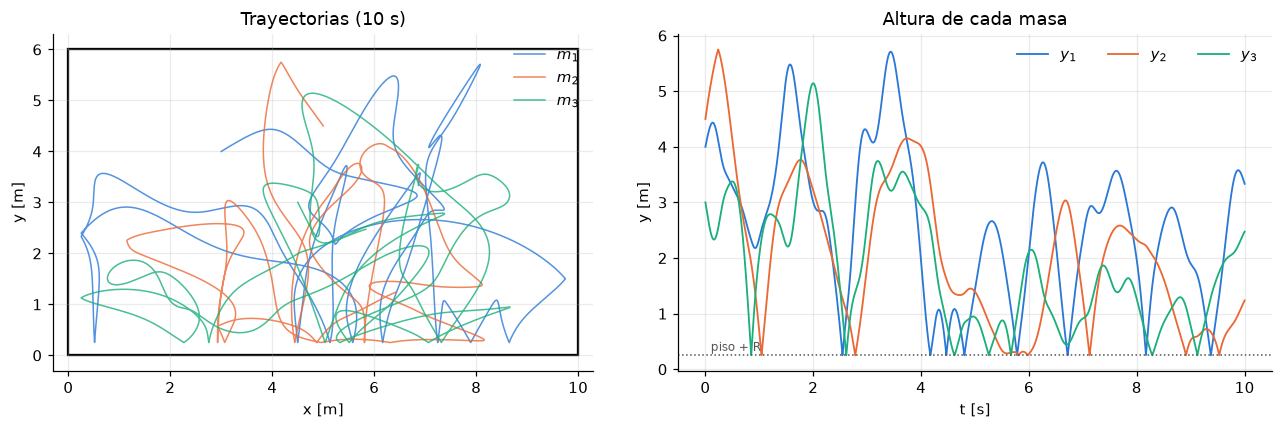

In [14]:
p = Parametros(
    pos0=[[3.0, 4.0], [5.0, 4.5], [4.5, 3.0]],
    vel0=[[8.0, 5.0], [-5.0, 7.0], [3.0, -6.0]],
    k=[40.0, 30.0, 50.0],
    b=0.1,
    m=[1.0, 1.5, 0.8],
    g=9.81,
    e=1.0,
)
h = 1e-3
print(f'h sugerido = {p.h_sugerido():.2e} s   ·   h usado = {h:.0e} s')
print('Longitudes naturales L1, L2, L3 =', np.round(p.L0, 3), 'm')

t, S = simular(p, T=10.0, h=h)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
ax = axs[0]
ax.add_patch(plt.Rectangle((0, 0), p.ancho, p.alto, fill=False, lw=1.5, color='k'))
for i in range(3):
    ax.plot(S[:, 2*i], S[:, 2*i+1], color=COLORES[i], lw=1, alpha=0.8, label=f'$m_{i+1}$')
ax.set_aspect('equal'); ax.set_xlim(-0.3, p.ancho+0.3); ax.set_ylim(-0.3, p.alto+0.3)
ax.set_title('Trayectorias (10 s)'); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
ax.legend(frameon=False, loc='upper right')

ax = axs[1]
for i in range(3):
    ax.plot(t, S[:, 2*i+1], color=COLORES[i], lw=1.2, label=f'$y_{i+1}$')
ax.axhline(p.radio, color=GRIS, ls=':', lw=1); ax.text(0.1, p.radio+0.08, 'piso + R', color=GRIS, fontsize=8)
ax.set_title('Altura de cada masa'); ax.set_xlabel('t [s]'); ax.set_ylabel('y [m]')
ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.show()

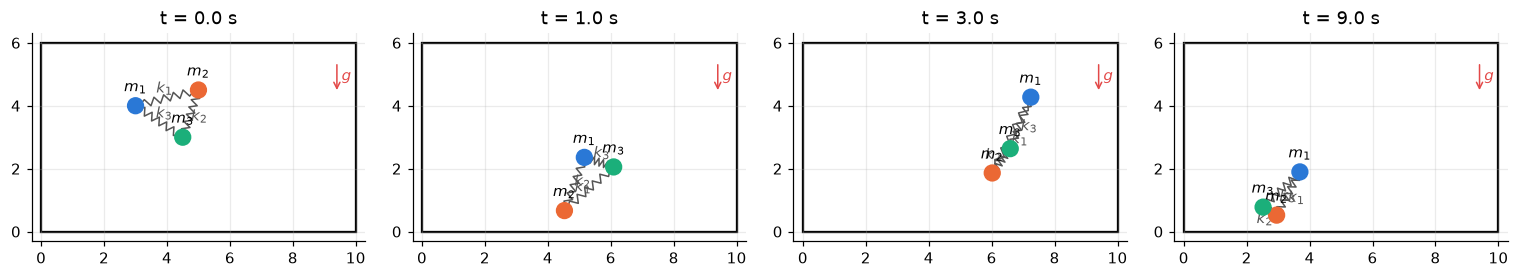

In [15]:
# Instantáneas del triángulo en distintos tiempos
fig, axs = plt.subplots(1, 4, figsize=(14, 2.8))
for ax, tk in zip(axs, [0, 1.0, 3.0, 9.0]):
    n = int(round(tk / h))
    dibujar_sistema(S[n, :6].reshape(3, 2), p.ancho, p.alto, p.radio, ax=ax, titulo=f't = {tk:.1f} s')
    ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

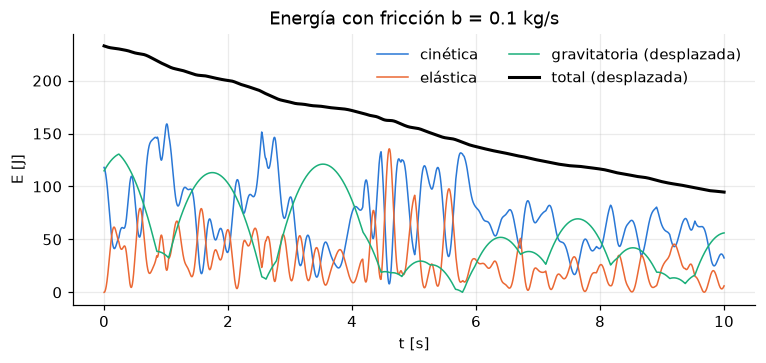

¿La energía total nunca aumenta (salvo error numérico)? True


In [16]:
# Balance de energía: con b > 0 la energía total debe decrecer monótonamente (dE/dt = -bΣ|v|² ≤ 0)
Ek, Ee, Eg = energia(S, p)
E = Ek + Ee + Eg
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(t, Ek, color=COLORES[0], lw=1, label='cinética')
ax.plot(t, Ee, color=COLORES[1], lw=1, label='elástica')
ax.plot(t, Eg - Eg.min(), color=COLORES[2], lw=1, label='gravitatoria (desplazada)')
ax.plot(t, E - Eg.min(), color='k', lw=2, label='total (desplazada)')
ax.set_xlabel('t [s]'); ax.set_ylabel('E [J]'); ax.set_title(f'Energía con fricción b = {p.b} kg/s')
ax.legend(frameon=False, ncol=2); plt.show()
print('¿La energía total nunca aumenta (salvo error numérico)?',
      np.all(np.diff(E) < 1e-9 * abs(E[0])))

---
## 5.6 Validación del código contra las soluciones analíticas

Un buen código numérico se valida contra **resultados que se conocen**. Hacemos seis pruebas:

| Prueba | Qué valida | Resultado esperado |
|---|---|---|
| A | Centro de masa vs. 3.1 | Error ~ precisión de máquina |
| B | Un resorte vs. 3.3 | Error muy pequeño |
| C | Modo de respiración vs. 3.4 (sistema completo) | Error muy pequeño |
| D | Orden de convergencia | Pendiente ≈ 4 (RK4) vs. ≈ 1 (Euler) |
| E | Conservación de energía con $b=0$, $e=1$ y rebotes | Rebote simple: deriva $O(h)$; con eventos: $\sim 10^{-8}$ |
| F | Contacto en reposo con $e<1$, $b>0$ | Energía decreciente; el sistema queda quieto en el piso |

### Prueba A: centro de masa (sección 3.1)
Masas iguales, resortes activos y sin paredes. El centro de masa debe seguir el tiro con fricción **aunque el triángulo vibre**.

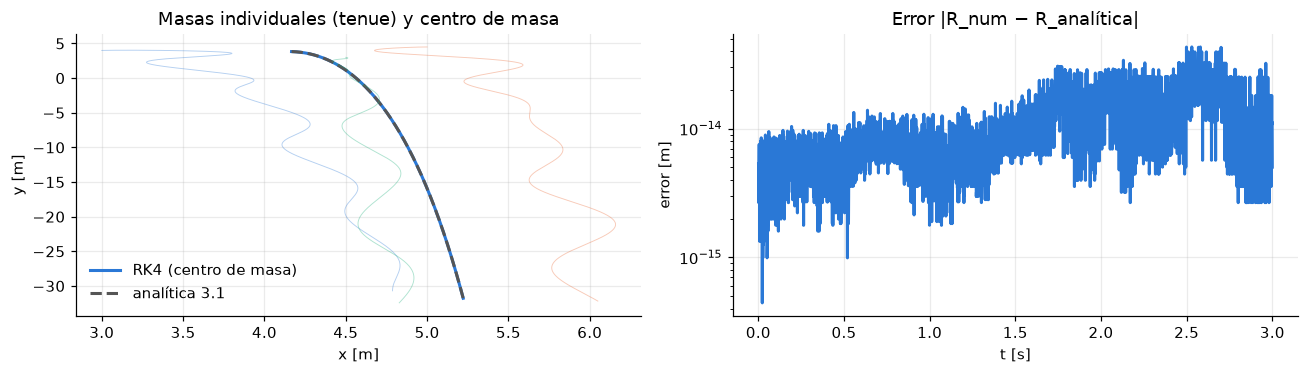

Error máximo del centro de masa: 4.31e-14 m


In [17]:
mA = 1.2
pA = Parametros(pos0=[[3, 4], [5, 4.5], [4.5, 3]], vel0=[[2, 1], [-1, 0], [0.5, -2]],
                k=[40, 30, 50], b=0.3, m=[mA]*3, g=9.81, rebotes=False)
L0_A = pA.L0.copy()
pA.L0 = L0_A * 0.8          # resortes pre-estirados: el triángulo vibra con fuerza
tA, SA = simular(pA, T=3.0, h=1e-3)

R_num = np.stack([SA[:, 0:6:2].mean(1), SA[:, 1:6:2].mean(1)], 1)   # masas iguales → promedio
R0, V0 = pA.pos0.mean(0), pA.vel0.mean(0)
gam = pA.b / mA
X_an = R0[0] + V0[0]/gam*(1 - np.exp(-gam*tA))
Y_an = R0[1] - pA.g/gam*tA + (V0[1] + pA.g/gam)/gam*(1 - np.exp(-gam*tA))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].plot(R_num[:, 0], R_num[:, 1], color=COLORES[0], label='RK4 (centro de masa)')
axs[0].plot(X_an, Y_an, '--', color=GRIS, label='analítica 3.1')
for i in range(3):
    axs[0].plot(SA[:, 2*i], SA[:, 2*i+1], color=COLORES[i], lw=0.6, alpha=0.35)
axs[0].set_title('Masas individuales (tenue) y centro de masa'); axs[0].legend(frameon=False)
axs[0].set_xlabel('x [m]'); axs[0].set_ylabel('y [m]')
err = np.hypot(R_num[:, 0] - X_an, R_num[:, 1] - Y_an)
axs[1].semilogy(tA[1:], err[1:], color=COLORES[0])
axs[1].set_title('Error |R_num − R_analítica|'); axs[1].set_xlabel('t [s]'); axs[1].set_ylabel('error [m]')
plt.tight_layout(); plt.show()
print(f'Error máximo del centro de masa: {err.max():.2e} m')

### Prueba B: un solo resorte (sección 3.3)
$k_2 = k_3 = 0$, $m_1 = m_2$, masas alineadas en $x$ con velocidades opuestas a lo largo de la línea y la misma $v_y$. La masa 3 queda libre y no influye.

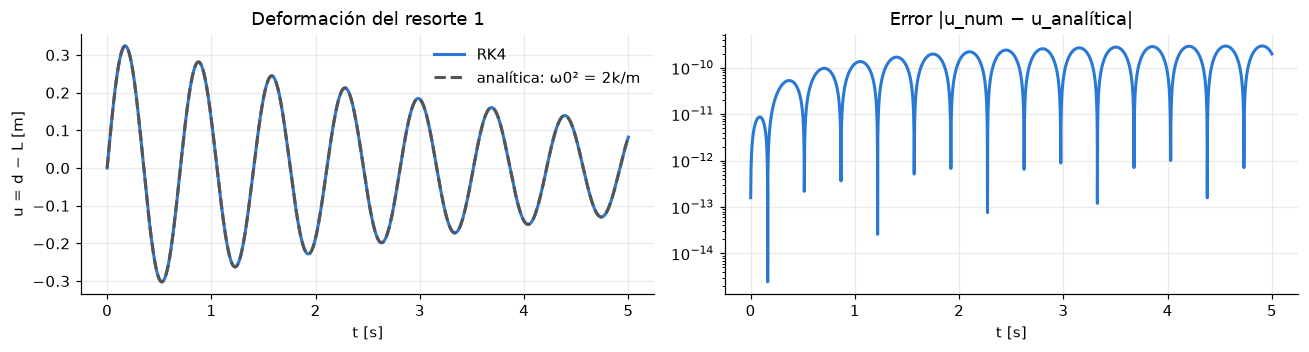

Error máximo: 2.94e-10 m


In [18]:
mB, kB, bB = 1.0, 40.0, 0.4
pB = Parametros(pos0=[[3, 4], [5, 4], [8, 2]], vel0=[[-1.5, 2.0], [1.5, 2.0], [0, 0]],
                k=[kB, 0, 0], b=bB, m=[mB, mB, 1.0], g=9.81, rebotes=False)
tB, SB = simular(pB, T=5.0, h=1e-3)

u_num = np.hypot(SB[:, 2] - SB[:, 0], SB[:, 3] - SB[:, 1]) - pB.L0[0]
u_an = oscilador_amortiguado(tB, 0.0, 3.0, np.sqrt(2*kB/mB), bB/mB)    # u0 = 0, du/dt(0) = 1.5-(-1.5)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.3))
axs[0].plot(tB, u_num, color=COLORES[0], label='RK4')
axs[0].plot(tB, u_an, '--', color=GRIS, label='analítica: ω0² = 2k/m')
axs[0].set_title('Deformación del resorte 1'); axs[0].set_xlabel('t [s]'); axs[0].set_ylabel('u = d − L [m]')
axs[0].legend(frameon=False)
axs[1].semilogy(tB[1:], np.abs(u_num - u_an)[1:] + 1e-18, color=COLORES[0])
axs[1].set_title('Error |u_num − u_analítica|'); axs[1].set_xlabel('t [s]')
plt.tight_layout(); plt.show()
print(f'Error máximo: {np.abs(u_num - u_an).max():.2e} m')

### Prueba C: modo de respiración del triángulo (sección 3.4)
Las 12 EDOs completas, con los 3 resortes, gravedad y fricción. La solución exacta es conocida.

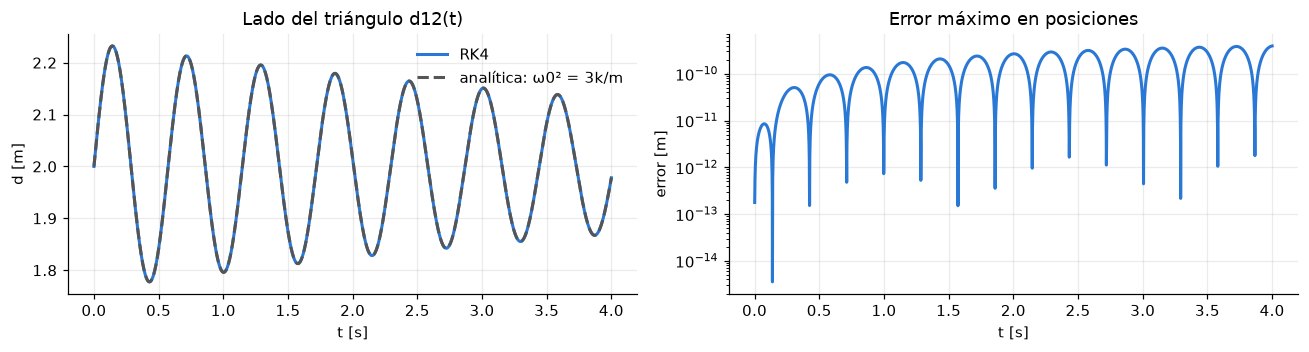

Error máximo en las 6 coordenadas: 3.93e-10 m


In [19]:
def caso_respiracion(m=1.0, k=40.0, b=0.3, g=9.81, Llado=2.0, v_rad=1.5, Vcm=(1.0, 2.0)):
    '''Triángulo equilátero con velocidades radiales iguales + velocidad común del centro de masa.'''
    rho0 = Llado / np.sqrt(3)
    angulos = np.deg2rad([90, 210, 330])
    e_hat = np.stack([np.cos(angulos), np.sin(angulos)], 1)        # direcciones centroide → vértice
    centro = np.array([5.0, 3.0])
    pos0 = centro + rho0 * e_hat
    vel0 = np.array(Vcm) + v_rad * e_hat
    p = Parametros(pos0=pos0, vel0=vel0, k=[k]*3, b=b, m=[m]*3, g=g, rebotes=False)

    def exacta(t):
        gam = b / m
        X = centro[0] + Vcm[0]/gam*(1 - np.exp(-gam*t))
        Y = centro[1] - g/gam*t + (Vcm[1] + g/gam)/gam*(1 - np.exp(-gam*t))
        u = oscilador_amortiguado(t, 0.0, v_rad, np.sqrt(3*k/m), gam)
        rho = rho0 + u
        return np.stack([np.stack([X + rho*e_hat[i, 0], Y + rho*e_hat[i, 1]], 1) for i in range(3)], 1)
    return p, exacta

pC, exactaC = caso_respiracion()
tC, SC = simular(pC, T=4.0, h=1e-3)
r_ex = exactaC(tC)                                   # (N, 3, 2)
errC = np.abs(SC[:, :6].reshape(-1, 3, 2) - r_ex).max(axis=(1, 2))

lado_num = np.linalg.norm(SC[:, 0:2] - SC[:, 2:4], axis=1)
lado_ex = np.linalg.norm(r_ex[:, 0] - r_ex[:, 1], axis=1)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.3))
axs[0].plot(tC, lado_num, color=COLORES[0], label='RK4')
axs[0].plot(tC, lado_ex, '--', color=GRIS, label='analítica: ω0² = 3k/m')
axs[0].set_title('Lado del triángulo d12(t)'); axs[0].set_xlabel('t [s]'); axs[0].set_ylabel('d [m]')
axs[0].legend(frameon=False)
axs[1].semilogy(tC[1:], errC[1:] + 1e-18, color=COLORES[0])
axs[1].set_title('Error máximo en posiciones'); axs[1].set_xlabel('t [s]'); axs[1].set_ylabel('error [m]')
plt.tight_layout(); plt.show()
print(f'Error máximo en las 6 coordenadas: {errC.max():.2e} m')

### Prueba D: orden de convergencia (RK4 vs. Euler)
Usamos el caso C, que tiene solución exacta, y medimos el error máximo para varios $h$. En escala log–log, la pendiente es el orden del método: $\text{error} \approx C\,h^p$.

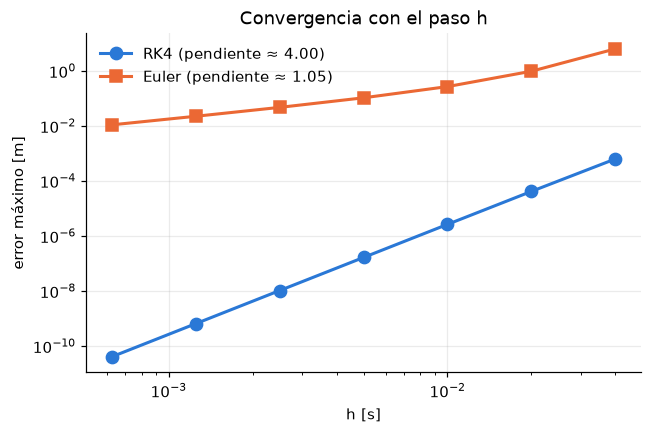

 h        error RK4    razón     error Euler
0.04     6.344e-04      nan    6.345e+00
0.02     4.192e-05     15.1    9.758e-01
0.01     2.655e-06     15.8    2.696e-01
0.005    1.665e-07     15.9    1.055e-01
0.0025   1.041e-08     16.0    4.731e-02
0.00125  6.510e-10     16.0    2.248e-02
0.000625 4.069e-11     16.0    1.096e-02

Pendientes medidas: RK4 ≈ 4.00, Euler ≈ 1.05
Al dividir h por 2, el error de RK4 se divide por ≈ 2⁴ = 16 y el de Euler solo por ≈ 2.


In [20]:
hs = np.array([0.04, 0.02, 0.01, 0.005, 0.0025, 0.00125, 0.000625])
err_rk4, err_eu = [], []
for hh in hs:
    for metodo, lista in [('rk4', err_rk4), ('euler', err_eu)]:
        tt_, SS = simular(pC, T=2.0, h=hh, metodo=metodo)
        lista.append(np.abs(SS[:, :6].reshape(-1, 3, 2) - exactaC(tt_)).max())
err_rk4, err_eu = np.array(err_rk4), np.array(err_eu)

# pendiente con los 3 pasos más pequeños (régimen asintótico, donde error ≈ C·h^p)
p_rk4 = np.polyfit(np.log(hs[-3:]), np.log(err_rk4[-3:]), 1)[0]
p_eu = np.polyfit(np.log(hs[-3:]), np.log(err_eu[-3:]), 1)[0]

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(hs, err_rk4, 'o-', color=COLORES[0], ms=8, label=f'RK4 (pendiente ≈ {p_rk4:.2f})')
ax.loglog(hs, err_eu, 's-', color=COLORES[1], ms=8, label=f'Euler (pendiente ≈ {p_eu:.2f})')
ax.set_xlabel('h [s]'); ax.set_ylabel('error máximo [m]'); ax.set_title('Convergencia con el paso h')
ax.legend(frameon=False); plt.show()

print(' h        error RK4    razón     error Euler')
for i, hh in enumerate(hs):
    razon = err_rk4[i-1]/err_rk4[i] if i else float('nan')
    print(f'{hh:<8} {err_rk4[i]:.3e}   {razon:6.1f}    {err_eu[i]:.3e}')
print(f'\nPendientes medidas: RK4 ≈ {p_rk4:.2f}, Euler ≈ {p_eu:.2f}')
print('Al dividir h por 2, el error de RK4 se divide por ≈ 2⁴ = 16 y el de Euler solo por ≈ 2.')

### Prueba E: conservación de energía con rebotes ($b = 0$, $e = 1$)
Es el sistema completo, con paredes y masas distintas. La energía debe mantenerse constante. Comparamos el rebote simple (al final del paso) con el rebote con localización del evento.

            |ΔE/E0| máximo en 10 s
 h          rebote simple   con eventos
 0.002      1.11e-02        3.01e-08
 0.001      8.46e-03        1.28e-08
 0.00025    8.79e-04        8.88e-09


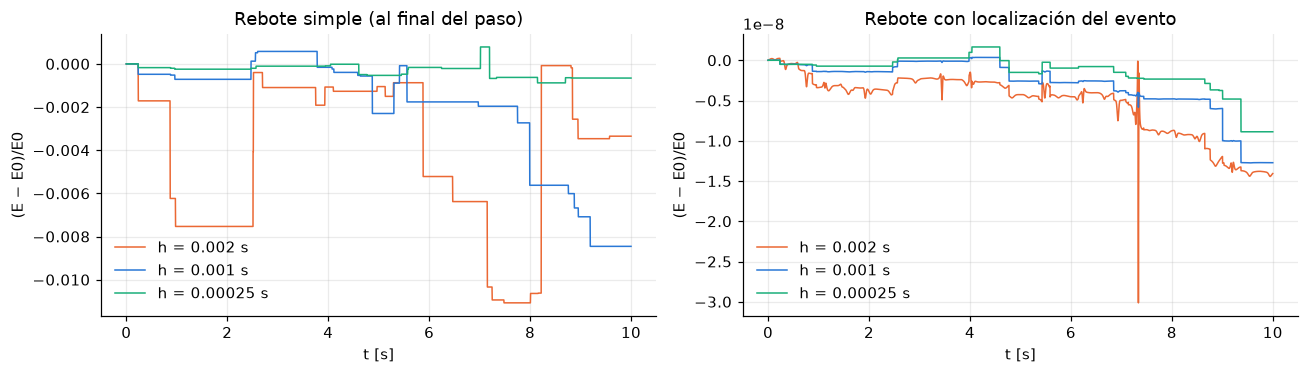

In [21]:
pE = Parametros(pos0=[[3, 4], [5, 4.5], [4.5, 3]], vel0=[[8, 5], [-5, 7], [3, -6]],
                k=[40, 30, 50], b=0.0, m=[1.0, 1.5, 0.8], g=9.81, e=1.0)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
print('            |ΔE/E0| máximo en 10 s')
print(' h          rebote simple   con eventos')
for hh, c in [(2e-3, COLORES[1]), (1e-3, COLORES[0]), (2.5e-4, COLORES[2])]:
    fila = []
    for ax, ev in zip(axs, [False, True]):
        tE, SE = simular(pE, T=10.0, h=hh, eventos=ev)
        E = sum(energia(SE, pE))
        dE = (E - E[0]) / abs(E[0])
        ax.plot(tE, dE, color=c, lw=1, label=f'h = {hh:g} s')
        fila.append(np.abs(dE).max())
    print(f' {hh:<10g} {fila[0]:.2e}        {fila[1]:.2e}')
axs[0].set_title('Rebote simple (al final del paso)'); axs[1].set_title('Rebote con localización del evento')
for ax in axs:
    ax.set_xlabel('t [s]'); ax.set_ylabel('(E − E0)/E0'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

Con el rebote simple, cada choque introduce un salto de energía $O(h)$ y los saltos se acumulan. Con la localización del evento, la energía se conserva hasta $\sim 10^{-8}$: queda solo el error de RK4. **Por eso `simular` usa eventos por defecto.**

### Prueba F: contacto en reposo ($e < 1$, $b > 0$)
Con rebotes inelásticos y fricción, el sistema debe perder energía y quedar quieto en el piso, sin que la simulación se trabe en micro-rebotes.

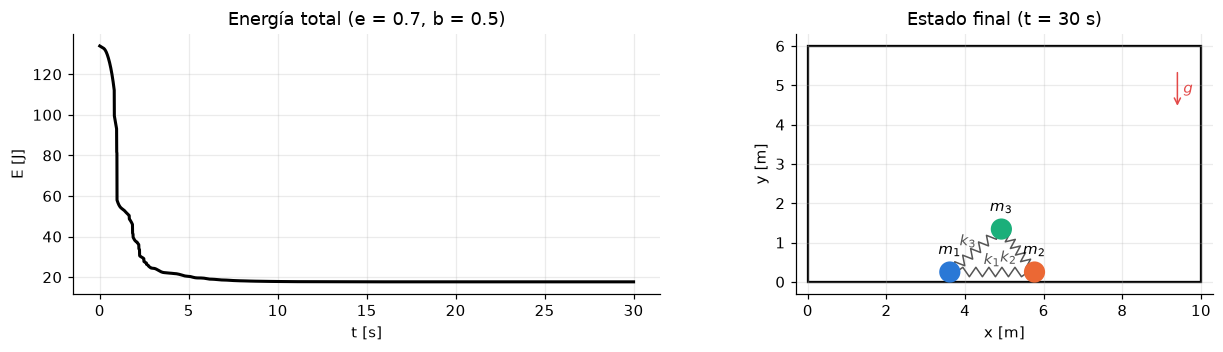

¿E nunca aumenta? True    ·   velocidad máxima final: 1.7e-03 m/s


In [22]:
pF = Parametros(pos0=[[3, 4], [5, 4.5], [4.5, 3]], vel0=[[2, 1], [-1, 0], [0.5, -2]],
                k=[40, 30, 50], b=0.5, m=[1.0, 1.5, 0.8], g=9.81, e=0.7)
tF, SF = simular(pF, T=30.0, h=1e-3)
EF = sum(energia(SF, pF))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.3))
axs[0].plot(tF, EF, color='k'); axs[0].set_title('Energía total (e = 0.7, b = 0.5)')
axs[0].set_xlabel('t [s]'); axs[0].set_ylabel('E [J]')
dibujar_sistema(SF[-1, :6].reshape(3, 2), pF.ancho, pF.alto, pF.radio, ax=axs[1], titulo='Estado final (t = 30 s)')
plt.tight_layout(); plt.show()
print('¿E nunca aumenta?', np.all(np.diff(EF) <= 1e-9 * abs(EF[0])),
      '   ·   velocidad máxima final:', f'{np.abs(SF[-1, 6:]).max():.1e} m/s')

---
## 5.7 Resumen para la presentación

**Física → EDOs.** Tres masas, tres resortes 2D (Hooke a lo largo de la línea que une las masas), gravedad y fricción lineal. Resultan 6 EDOs de segundo orden, **no lineales** por $d_{ij}$, que se reducen a **12 EDOs de primer orden** $\dot{\mathbf S} = \mathbf f(\mathbf S)$.

**Analítica.** El sistema completo no tiene solución cerrada. Sí la tienen tres casos:
- el **centro de masa** (tiro con fricción lineal, masas iguales);
- **un resorte** entre dos masas iguales (oscilador amortiguado con $\omega_0^2 = 2k/m$);
- el **modo de respiración** del triángulo equilátero ($\omega_0^2 = 3k/m$, exacto incluso siendo no lineal).

La linealización da las frecuencias normales $\{0, 0, 0, \tfrac{3k}{2m}, \tfrac{3k}{2m}, \tfrac{3k}{m}\}$: tres modos rígidos y tres de deformación.

**Discretización.** Malla $t_n = nh$ y RK4 (4 pendientes con pesos tipo Simpson, error global $O(h^4)$). Los rebotes se tratan como eventos: se localiza por bisección el instante del choque dentro del paso, y se maneja el contacto en reposo. El paso se elige con $h \le T_{\min}/100$.

**Validación.**
- RK4 reproduce las tres soluciones exactas.
- La pendiente de convergencia medida es ≈ 4 para RK4 y ≈ 1 para Euler.
- Con $b = 0$ y $e = 1$ la energía se conserva hasta $\sim 10^{-8}$ gracias a la localización de eventos; con el rebote simple la deriva es de varios por ciento.
- Con $e < 1$ y $b > 0$ el sistema pierde energía y queda en reposo en el piso.

**Siguientes pasos:** animación con `FuncAnimation` y una GUI (Tkinter) que construya un `Parametros` con los 20 valores y llame a `simular`.